# comparaison des methodes ADAPT : shift frequency

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from adapt_utils import run_all_methods

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Execution (sans et avec standardisation)

In [2]:
shift_type = "frequency"

results_raw = run_all_methods(shift_type, standardize=False)
results_std = run_all_methods(shift_type, standardize=True)

results_raw["standardise"] = False
results_std["standardise"] = True
results_df = pd.concat([results_raw, results_std], ignore_index=True)
results_df

,method,intensity,mse_source,mse_target,r2_source,r2_target,standardise
0,sans adaptation,0.25,0.033010,0.036298,0.951031,0.940331,False
1,sans adaptation,0.50,0.033010,0.061869,0.951031,0.908806,False
2,sans adaptation,1.00,0.033010,0.259065,0.951031,0.620755,False
3,CORAL,0.25,0.033010,1.991722,0.951031,-2.274135,False
4,CORAL,0.50,0.033010,1.995008,0.951031,-1.940601,False
5,CORAL,1.00,0.033010,2.119610,0.951031,-2.102886,False
6,SA,0.25,0.033010,0.683195,0.951031,-0.123084,False
7,SA,0.50,0.033010,0.725509,0.951031,-0.069385,False
8,SA,1.00,0.033010,0.959048,0.951031,-0.403946,False
9,TCA,0.25,3.906663,3.454794,-4.795342,-4.679236,False


## Comparaison (r2 cible)

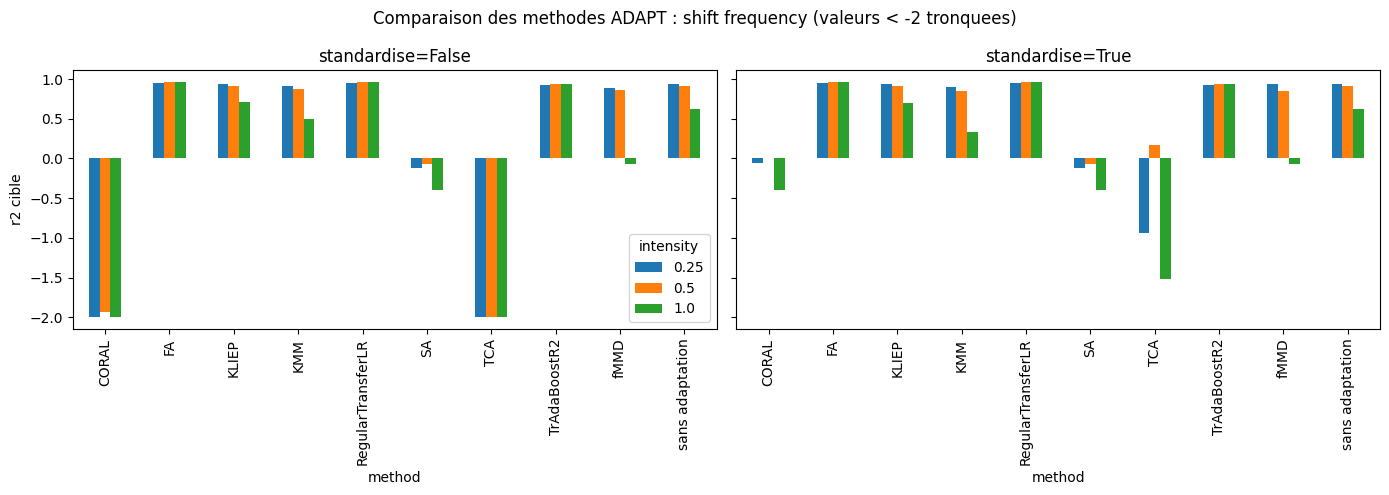

In [3]:
plot_floor = -2

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, standardise in zip(axes, [False, True]):
    subset = results_df[results_df["standardise"] == standardise]
    pivot = subset.pivot(index="method", columns="intensity", values="r2_target").clip(lower=plot_floor)
    pivot.plot(kind="bar", ax=ax, legend=(ax is axes[0]))
    ax.set_title(f"standardise={standardise}")
    ax.set_ylabel("r2 cible")

plt.suptitle(f"Comparaison des methodes ADAPT : shift {shift_type} (valeurs < {plot_floor} tronquees)")
plt.tight_layout()
plt.show()

## Source vs cible (sans standardisation)

In [4]:
subset = results_df[~results_df["standardise"]]
subset.pivot_table(index="method", columns="intensity", values=["r2_source", "r2_target"])

r2_source                     r2_target                    
intensity              0.25      0.50      1.00      0.25      0.50      1.00
method                                                                       
CORAL              0.951031  0.951031  0.951031 -2.274135 -1.940601 -2.102886
FA                 0.950989  0.950899  0.950452  0.950230  0.956967  0.960917
KLIEP              0.945874  0.946628  0.946894  0.938045  0.917038  0.712006
KMM                0.923899  0.926609  0.929638  0.913159  0.874385  0.495088
RegularTransferLR  0.942862  0.919052  0.748617  0.950342  0.957112  0.961381
SA                 0.951031  0.951031  0.951031 -0.123084 -0.069385 -0.403946
TCA               -4.795342 -9.766499 -7.803148 -4.679236 -8.000606 -4.623077
TrAdaBoostR2       0.922196  0.878992  0.313582  0.920164  0.931211  0.931154
fMMD               0.926290  0.945709  0.940308  0.885168  0.865837 -0.073612
sans adaptation    0.951031  0.951031  0.951031  0.940331  0.908806  0.620755

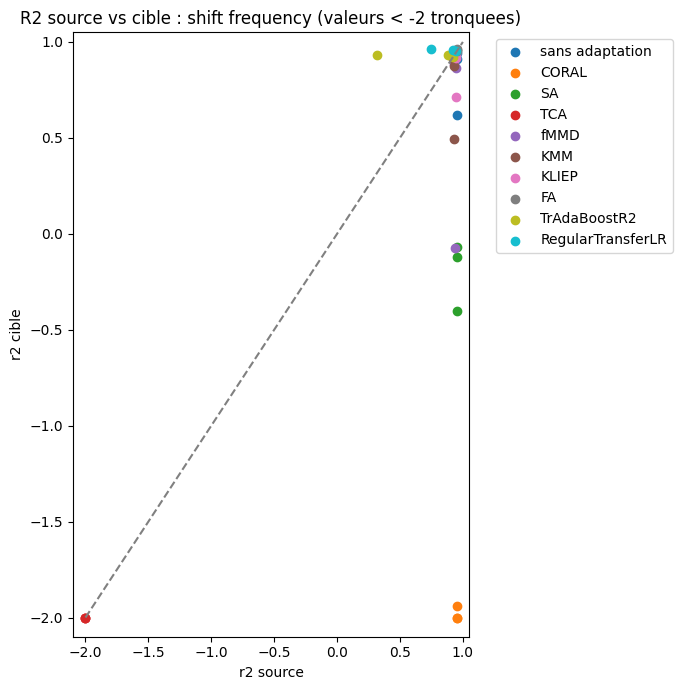

In [5]:
plot_floor = -2

fig, ax = plt.subplots(figsize=(7, 7))
for method in subset["method"].unique():
    method_data = subset[subset["method"] == method]
    x = method_data["r2_source"].clip(lower=plot_floor)
    y = method_data["r2_target"].clip(lower=plot_floor)
    ax.scatter(x, y, label=method)

ax.plot([plot_floor, 1], [plot_floor, 1], linestyle="--", color="gray")
ax.set_xlim(plot_floor - 0.1, 1.05)
ax.set_ylim(plot_floor - 0.1, 1.05)
ax.set_xlabel("r2 source")
ax.set_ylabel("r2 cible")
ax.set_title(f"R2 source vs cible : shift {shift_type} (valeurs < {plot_floor} tronquees)")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()